In [6]:
import torch
import torchvision
import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("MPS available:", torch.backends.mps.is_available())


PyTorch: 2.14.0
Torchvision: 0.29.0
MPS available: True


In [2]:

from torchvision import datasets, transforms

transform = transforms.ToTensor()

train_data = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_data = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training images:", len(train_data))
print("Testing images:", len(test_data))


100.0%


Training images: 50000
Testing images: 10000


Image tensor shape: torch.Size([3, 32, 32])
Class label: frog


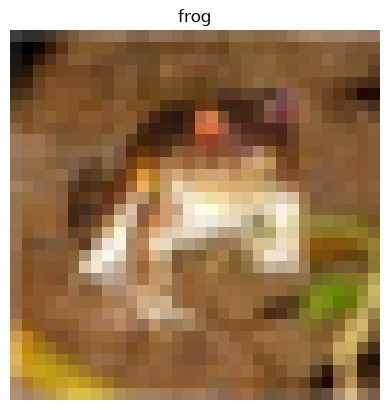

In [8]:

image, label = train_data[0]
imgshow = image
print("Image tensor shape:", image.shape)
print("Class label:", train_data.classes[label])

plt.imshow(image.permute(1, 2, 0))
plt.title(train_data.classes[label])
plt.axis("off")
plt.show()


In [9]:

from torch.utils.data import DataLoader

batch_size = 64

train_loader = DataLoader(
    train_data,
    batch_size=batch_size,
    shuffle=True
)

test_loader = DataLoader(
    test_data,
    batch_size=batch_size,
    shuffle=False
)

images, labels = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)


Batch image shape: torch.Size([64, 3, 32, 32])
Batch label shape: torch.Size([64])


In [10]:

import torch.nn as nn

class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3072, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.network(x)

model = MLP()
print(model)


MLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [11]:

import torch.optim as optim

device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

model = MLP().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Training device:", device)
print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)


Training device: mps
Loss function: CrossEntropyLoss()
Optimizer: Adam


In [13]:

epochs = 3

for epoch in range(epochs):
    model.train()
    running_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    average_loss = running_loss / len(train_loader)

    print(
        f"Epoch {epoch + 1}/{epochs}, "
        f"Average Loss: {average_loss:.4f}"
    )


Epoch 1/3, Average Loss: 1.6346
Epoch 2/3, Average Loss: 1.6093
Epoch 3/3, Average Loss: 1.5906


In [14]:

model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
test_error = 100 - accuracy

print(f"Test Accuracy: {accuracy:.2f}%")
print(f"Test Error: {test_error:.2f}%")


Test Accuracy: 43.70%
Test Error: 56.30%


In [15]:

class CNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Flatten(),
            nn.Linear(32 * 8 * 8, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.network(x)

cnn_model = CNN().to(device)

print(cnn_model)


CNN(
  (network): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Flatten(start_dim=1, end_dim=-1)
    (7): Linear(in_features=2048, out_features=128, bias=True)
    (8): ReLU()
    (9): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [16]:

cnn_criterion = nn.CrossEntropyLoss()

cnn_optimizer = optim.Adam(
    cnn_model.parameters(),
    lr=0.001
)

print("CNN ready for training!")


CNN ready for training!


In [17]:

cnn_epochs = 3

for epoch in range(cnn_epochs):
    cnn_model.train()
    running_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        cnn_optimizer.zero_grad()

        outputs = cnn_model(images)
        loss = cnn_criterion(outputs, labels)

        loss.backward()
        cnn_optimizer.step()

        running_loss += loss.item()

    average_loss = running_loss / len(train_loader)

    print(
        f"CNN Epoch {epoch + 1}/{cnn_epochs}, "
        f"Average Loss: {average_loss:.4f}"
    )


CNN Epoch 1/3, Average Loss: 1.6092
CNN Epoch 2/3, Average Loss: 1.2681
CNN Epoch 3/3, Average Loss: 1.1261


In [18]:

cnn_model.eval()

cnn_correct = 0
cnn_total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = cnn_model(images)
        _, predicted = torch.max(outputs, 1)

        cnn_total += labels.size(0)
        cnn_correct += (predicted == labels).sum().item()

cnn_accuracy = 100 * cnn_correct / cnn_total
cnn_test_error = 100 - cnn_accuracy

print(f"CNN Test Accuracy: {cnn_accuracy:.2f}%")
print(f"CNN Test Error: {cnn_test_error:.2f}%")


CNN Test Accuracy: 60.99%
CNN Test Error: 39.01%


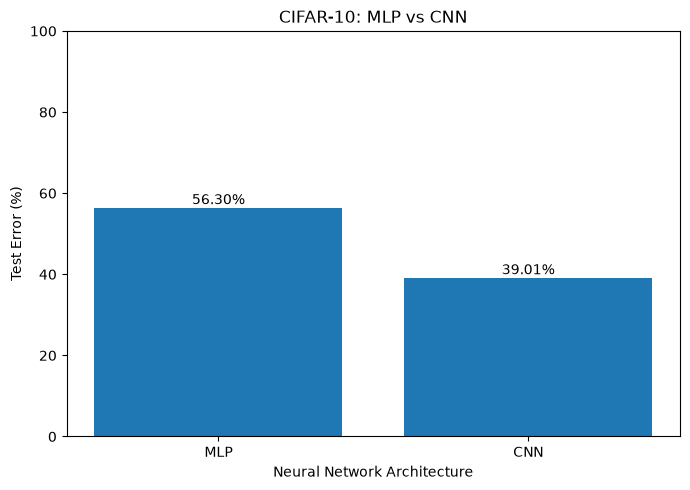

In [19]:

models = ["MLP", "CNN"]
errors = [test_error, cnn_test_error]

plt.figure(figsize=(7, 5))

bars = plt.bar(models, errors)

plt.xlabel("Neural Network Architecture")
plt.ylabel("Test Error (%)")
plt.title("CIFAR-10: MLP vs CNN")
plt.ylim(0, 100)

for bar, error in zip(bars, errors):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{error:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.savefig("mlp_vs_cnn_test_error.png", dpi=200)
plt.show()


In [20]:

from torch.utils.data import random_split, DataLoader

generator = torch.Generator().manual_seed(42)

training_subset, validation_subset = random_split(
    train_data,
    [45000, 5000],
    generator=generator
)

experiment_train_loader = DataLoader(
    training_subset,
    batch_size=64,
    shuffle=True
)

validation_loader = DataLoader(
    validation_subset,
    batch_size=64,
    shuffle=False
)

print("Training samples:", len(training_subset))
print("Validation samples:", len(validation_subset))
print("Testing samples:", len(test_data))


Training samples: 45000
Validation samples: 5000
Testing samples: 10000


In [21]:

def train_and_evaluate(model, train_loader, eval_loader, epochs, lr):
    model = model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    # Training
    for epoch in range(epochs):
        model.train()

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

    # Evaluation
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in eval_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            predicted = outputs.argmax(dim=1)

            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    accuracy = 100 * correct / total
    error = 100 - accuracy

    return error


In [48]:

learning_rates = [0.0001, 0.001, 0.01]
learning_rate_errors = []

for lr in learning_rates:
    torch.manual_seed(42)

    experiment_model = MLP()

    error = train_and_evaluate(
        model=experiment_model,
        train_loader=experiment_train_loader,
        eval_loader=test_loader,
        epochs=3,
        lr=lr
    )

    learning_rate_errors.append(error)

    print(f"Learning Rate: {lr} | Test Error: {error:.2f}%")


Learning Rate: 0.0001 | Test Error: 61.61%
Learning Rate: 0.001 | Test Error: 57.64%
Learning Rate: 0.01 | Test Error: 78.78%


In [23]:
learning_rates = [0.0001, 0.001, 0.01]

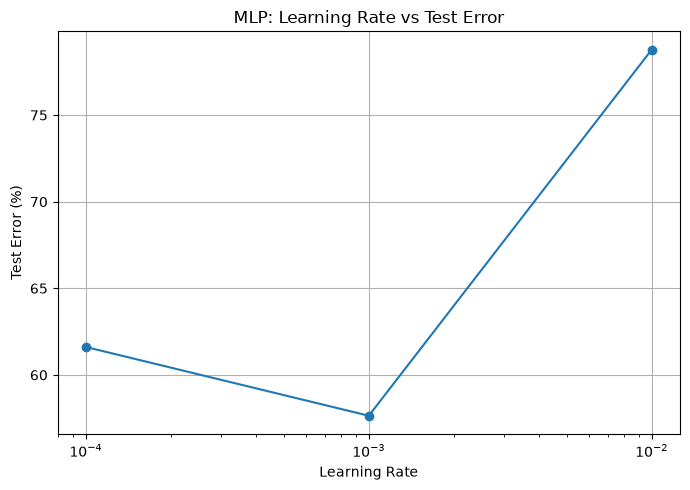

In [61]:

plt.figure(figsize=(7, 5))

plt.plot(
    learning_rates,
    learning_rate_errors,
    marker="o"
)

plt.xscale("log")
plt.xlabel("Learning Rate")
plt.ylabel("Test Error (%)")
plt.title("MLP: Learning Rate vs Test Error")

plt.grid(True)
plt.tight_layout()

plt.savefig("learning_rate_test_error.png", dpi=200)
plt.show()


In [51]:

torch.manual_seed(42)

epoch_model = MLP().to(device)

epoch_optimizer = optim.Adam(
    epoch_model.parameters(),
    lr=0.001
)

epoch_criterion = nn.CrossEntropyLoss()

epoch_numbers = []
epoch_errors = []

for epoch in range(5):
    epoch_model.train()

    for images, labels in experiment_train_loader:
        images = images.to(device)
        labels = labels.to(device)

        epoch_optimizer.zero_grad()

        outputs = epoch_model(images)
        loss = epoch_criterion(outputs, labels)

        loss.backward()
        epoch_optimizer.step()

    # Evaluate after each epoch
    epoch_model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = epoch_model(images)
            predicted = outputs.argmax(dim=1)

            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    error = 100 * (1 - correct / total)

    epoch_numbers.append(epoch + 1)
    epoch_errors.append(error)

    print(f"Epoch {epoch + 1}: Test Error = {error:.2f}%")


Epoch 1: Test Error = 64.04%
Epoch 2: Test Error = 62.40%
Epoch 3: Test Error = 57.38%
Epoch 4: Test Error = 55.76%
Epoch 5: Test Error = 55.67%


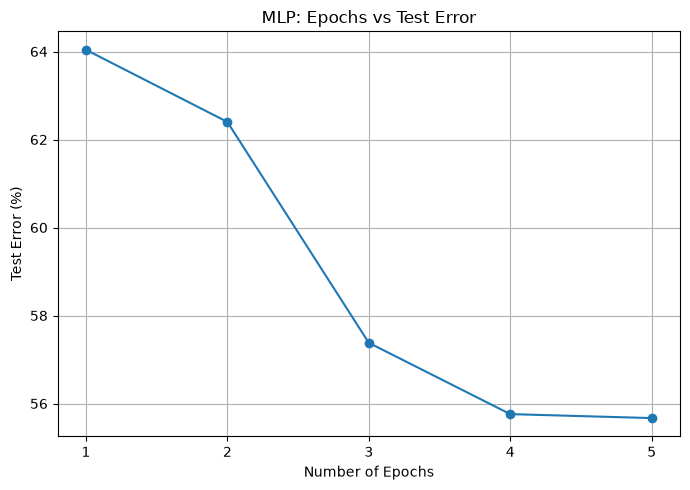

In [62]:

plt.figure(figsize=(7, 5))

plt.plot(
    epoch_numbers,
    epoch_errors,
    marker="o"
)

plt.xlabel("Number of Epochs")
plt.ylabel("Test Error (%)")
plt.title("MLP: Epochs vs Test Error")

plt.xticks(epoch_numbers)
plt.grid(True)

plt.tight_layout()
plt.savefig("epochs_vs_test_error.png", dpi=200)
plt.show()


In [53]:

batch_sizes = [16, 32, 64, 128]
batch_size_errors = []

for batch_size in batch_sizes:

    torch.manual_seed(42)

    batch_train_loader = DataLoader(
        training_subset,
        batch_size=batch_size,
        shuffle=True,
        generator=torch.Generator().manual_seed(42)
    )

    experiment_model = MLP()

    error = train_and_evaluate(
        model=experiment_model,
        train_loader=batch_train_loader,
        eval_loader=test_loader,
        epochs=3,
        lr=0.001
    )

    batch_size_errors.append(error)

    print(
        f"Batch Size: {batch_size} | "
        f"Test Error: {error:.2f}%"
    )


Batch Size: 16 | Test Error: 59.71%
Batch Size: 32 | Test Error: 58.40%
Batch Size: 64 | Test Error: 57.92%
Batch Size: 128 | Test Error: 57.95%


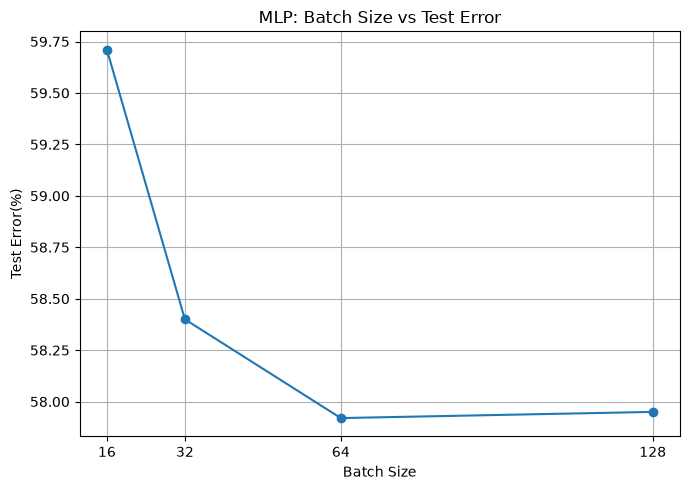

In [63]:

plt.figure(figsize=(7, 5))

plt.plot(
    batch_sizes,
    batch_size_errors,
    marker="o"
)

plt.xlabel("Batch Size")
plt.ylabel("Test Error(%)")
plt.title("MLP: Batch Size vs Test Error")

plt.xticks(batch_sizes)
plt.grid(True)

plt.tight_layout()
plt.savefig("batch_size_test_error.png", dpi=200)
plt.show()


In [29]:

class FlexibleMLP(nn.Module):
    def __init__(self, hidden_neurons):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3072, hidden_neurons),
            nn.ReLU(),
            nn.Linear(hidden_neurons, 10)
        )

    def forward(self, x):
        return self.network(x)


In [55]:

hidden_sizes = [64, 128, 256]
hidden_errors = []

for neurons in hidden_sizes:
    torch.manual_seed(42)

    experiment_model = FlexibleMLP(
        hidden_neurons=neurons
    )

    error = train_and_evaluate(
        model=experiment_model,
        train_loader=experiment_train_loader,
        eval_loader=test_loader,
        epochs=3,
        lr=0.001
    )

    hidden_errors.append(error)

    print(
        f"Hidden Neurons: {neurons} | "
        f"Test Error: {error:.2f}%"
    )


Hidden Neurons: 64 | Test Error: 59.71%
Hidden Neurons: 128 | Test Error: 57.64%
Hidden Neurons: 256 | Test Error: 57.76%


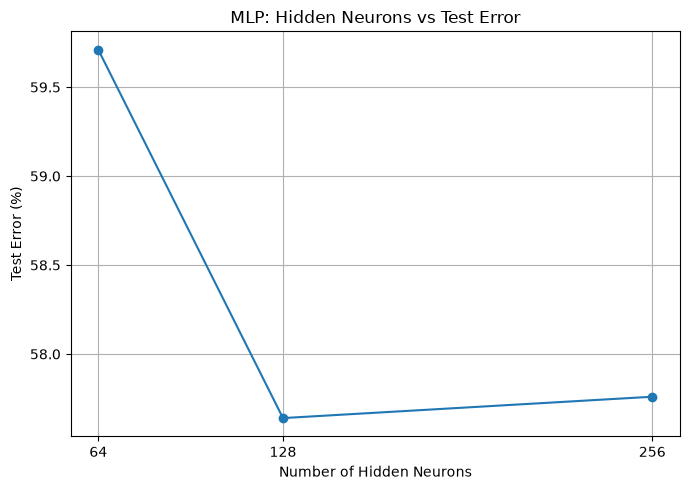

In [64]:

plt.figure(figsize=(7, 5))

plt.plot(
    hidden_sizes,
    hidden_errors,
    marker="o"
)

plt.xlabel("Number of Hidden Neurons")
plt.ylabel("Test Error (%)")
plt.title("MLP: Hidden Neurons vs Test Error")

plt.xticks(hidden_sizes)
plt.grid(True)

plt.tight_layout()
plt.savefig("hidden_neurons_test_error.png", dpi=200)
plt.show()


In [32]:

class DeepMLP(nn.Module):
    def __init__(self, hidden_layers):
        super().__init__()

        layers = [nn.Flatten()]
        input_size = 3072

        for neurons in hidden_layers:
            layers.append(nn.Linear(input_size, neurons))
            layers.append(nn.ReLU())
            input_size = neurons

        layers.append(nn.Linear(input_size, 10))

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


In [57]:

layer_configs = [
    [128],
    [128, 64],
    [128, 64, 32]
]

layer_counts = []
layer_errors = []

for config in layer_configs:
    torch.manual_seed(42)

    experiment_model = DeepMLP(config)

    error = train_and_evaluate(
        model=experiment_model,
        train_loader=experiment_train_loader,
        eval_loader=test_loader,
        epochs=3,
        lr=0.001
    )

    layer_counts.append(len(config))
    layer_errors.append(error)

    print(
        f"Hidden Layers: {len(config)} | "
        f"Test Error: {error:.2f}%"
    )


Hidden Layers: 1 | Test Error: 57.64%
Hidden Layers: 2 | Test Error: 57.05%
Hidden Layers: 3 | Test Error: 60.01%


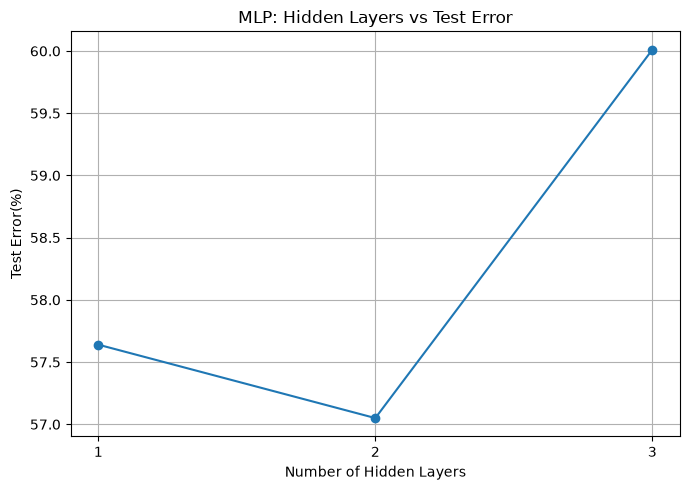

In [65]:

plt.figure(figsize=(7, 5))

plt.plot(
    layer_counts,
    layer_errors,
    marker="o"
)

plt.xlabel("Number of Hidden Layers")
plt.ylabel("Test Error(%)")
plt.title("MLP: Hidden Layers vs Test Error")

plt.xticks(layer_counts)
plt.grid(True)

plt.tight_layout()
plt.savefig("hidden_layers_test_error.png", dpi=200)
plt.show()


In [35]:

class FlexibleCNN(nn.Module):
    def __init__(self, kernel_size=3, pooling="max"):
        super().__init__()

        padding = kernel_size // 2

        if pooling == "max":
            pool = nn.MaxPool2d
        elif pooling == "avg":
            pool = nn.AvgPool2d
        else:
            raise ValueError("Use 'max' or 'avg'")

        self.network = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size,
                      padding=padding),
            nn.ReLU(),
            pool(2),

            nn.Conv2d(16, 32, kernel_size,
                      padding=padding),
            nn.ReLU(),
            pool(2),

            nn.Flatten(),
            nn.Linear(32 * 8 * 8, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.network(x)


In [59]:

cnn_configs = [
    (3, "max"),
    (5, "max"),
    (3, "avg"),
    (5, "avg")
]

cnn_config_errors = []

for kernel_size, pooling in cnn_configs:
    torch.manual_seed(42)

    experiment_model = FlexibleCNN(
        kernel_size=kernel_size,
        pooling=pooling
    )

    error = train_and_evaluate(
        model=experiment_model,
        train_loader=experiment_train_loader,
        eval_loader=test_loader,
        epochs=3,
        lr=0.001
    )

    cnn_config_errors.append(error)

    print(
        f"Kernel: {kernel_size}x{kernel_size} | "
        f"Pooling: {pooling} | "
        f"Test Error: {error:.2f}%"
    )


Kernel: 3x3 | Pooling: max | Test Error: 38.92%
Kernel: 5x5 | Pooling: max | Test Error: 37.90%
Kernel: 3x3 | Pooling: avg | Test Error: 43.92%
Kernel: 5x5 | Pooling: avg | Test Error: 43.73%


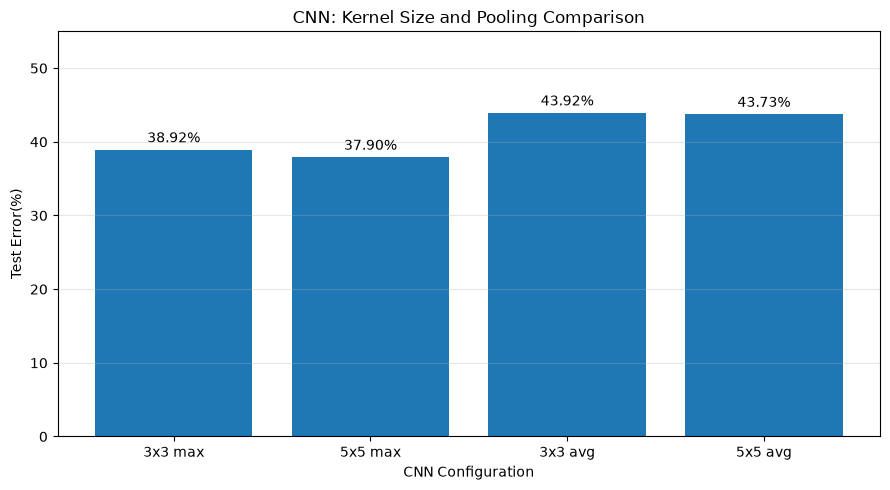

In [60]:

config_labels = [
    f"{kernel}x{kernel} {pooling}"
    for kernel, pooling in cnn_configs
]

plt.figure(figsize=(9, 5))

bars = plt.bar(config_labels, cnn_config_errors)

plt.xlabel("CNN Configuration")
plt.ylabel("Test Error(%)")
plt.title("CNN: Kernel Size and Pooling Comparison")

plt.bar_label(bars, fmt="%.2f%%", padding=3)
plt.ylim(0, 55)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("cnn_kernel_pooling_comparison.png", dpi=200)
plt.show()


In [39]:

# Final CNN training
torch.manual_seed(42)

device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

final_train_loader = DataLoader(
    train_data,
    batch_size=64,
    shuffle=True
)

final_cnn = FlexibleCNN(
    kernel_size=5,
    pooling="max"
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    final_cnn.parameters(),
    lr=0.001
)

final_cnn.train()

for epoch in range(3):
    running_loss = 0.0

    for images, labels in final_train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = final_cnn(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    avg_loss = running_loss / len(train_data)

    print(
        f"Final CNN Epoch {epoch + 1}/3 | "
        f"Average Loss: {avg_loss:.4f}"
    )


Final CNN Epoch 1/3 | Average Loss: 1.5356
Final CNN Epoch 2/3 | Average Loss: 1.1887
Final CNN Epoch 3/3 | Average Loss: 1.0314


In [40]:

# Final CNN test evaluation

final_test_loader = DataLoader(
    test_data,
    batch_size=64,
    shuffle=False
)

final_cnn.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in final_test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = final_cnn(images)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

final_accuracy = 100 * correct / total
final_error = 100 - final_accuracy

print(f"Final CNN Test Accuracy: {final_accuracy:.2f}%")
print(f"Final CNN Test Error: {final_error:.2f}%")


Final CNN Test Accuracy: 63.55%
Final CNN Test Error: 36.45%
